In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

sns.set_style("whitegrid")

In [2]:
PATH_ROOT=Path("../").resolve()
PATH_ROOT

PosixPath('/home/yparomau/Projects/superconduct-tc-reg')

## KMeans

### Without dimensionality reduction

In [3]:
df_scaled = pd.read_csv(PATH_ROOT/"data/processed/train-minmax-no_cfs-no_pca.csv")
with pd.option_context('display.max_columns', 82):
    display(df_scaled)

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,wtd_std_atomic_mass,mean_fie,wtd_mean_fie,gmean_fie,wtd_gmean_fie,entropy_fie,wtd_entropy_fie,range_fie,wtd_range_fie,std_fie,wtd_std_fie,mean_atomic_radius,wtd_mean_atomic_radius,gmean_atomic_radius,wtd_gmean_atomic_radius,entropy_atomic_radius,wtd_entropy_atomic_radius,range_atomic_radius,wtd_range_atomic_radius,std_atomic_radius,wtd_std_atomic_radius,mean_Density,wtd_mean_Density,gmean_Density,wtd_gmean_Density,entropy_Density,wtd_entropy_Density,range_Density,wtd_range_Density,std_Density,wtd_std_Density,mean_ElectronAffinity,wtd_mean_ElectronAffinity,gmean_ElectronAffinity,wtd_gmean_ElectronAffinity,entropy_ElectronAffinity,wtd_entropy_ElectronAffinity,range_ElectronAffinity,wtd_range_ElectronAffinity,std_ElectronAffinity,wtd_std_ElectronAffinity,mean_FusionHeat,wtd_mean_FusionHeat,gmean_FusionHeat,wtd_gmean_FusionHeat,entropy_FusionHeat,wtd_entropy_FusionHeat,range_FusionHeat,wtd_range_FusionHeat,std_FusionHeat,wtd_std_FusionHeat,mean_ThermalConductivity,wtd_mean_ThermalConductivity,gmean_ThermalConductivity,wtd_gmean_ThermalConductivity,entropy_ThermalConductivity,wtd_entropy_ThermalConductivity,range_ThermalConductivity,wtd_range_ThermalConductivity,std_ThermalConductivity,wtd_std_ThermalConductivity,mean_Valence,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,0.375,0.405879,0.253950,0.299720,0.164988,0.595724,0.542536,0.590973,0.154652,0.514443,0.530813,0.426541,0.652699,0.365457,0.590821,0.605237,0.388258,0.621388,0.587916,0.648049,0.742051,0.449000,0.230057,0.352504,0.146114,0.587893,0.634033,0.800781,0.178687,0.651407,0.712735,0.205986,0.131043,0.032031,0.002340,0.528645,0.478213,0.396598,0.070410,0.308285,0.343158,0.247497,0.339578,0.180601,0.301647,0.656031,0.469966,0.364040,0.370317,0.315747,0.251712,0.063787,0.034596,0.031089,0.007816,0.535082,0.569493,0.122907,0.016991,0.089069,0.090303,0.324026,0.149874,0.022135,0.001593,0.188588,0.162957,0.930227,0.142307,0.785419,0.649399,0.208333,0.209524,0.202227,0.203297,0.639097,0.546853,0.166667,0.155275,0.144338,0.145686,29.00
1,0.500,0.424611,0.257187,0.332968,0.166341,0.730573,0.540166,0.590973,0.175894,0.466193,0.534350,0.416958,0.653053,0.368073,0.591586,0.715618,0.395906,0.621388,0.593650,0.580747,0.740800,0.452800,0.227886,0.373861,0.145481,0.704181,0.632497,0.800781,0.210570,0.582869,0.700106,0.257655,0.133678,0.054703,0.002364,0.672591,0.537038,0.464331,0.074323,0.351294,0.348926,0.275385,0.341394,0.210515,0.307044,0.807813,0.500577,0.364040,0.371327,0.303497,0.246443,0.072175,0.034118,0.039911,0.007762,0.675860,0.614192,0.122907,0.015541,0.086634,0.089067,0.517872,0.150751,0.050456,0.001587,0.518614,0.351959,0.999998,0.128072,0.923569,0.654621,0.166667,0.209524,0.148029,0.201780,0.726956,0.537109,0.333333,0.161404,0.210819,0.156202,26.00
2,0.375,0.405879,0.254061,0.299720,0.165017,0.595724,0.498406,0.590973,0.173847,0.514443,0.531147,0.426541,0.653266,0.365457,0.591863,0.605237,0.379493,0.621388,0.593650,0.648049,0.740468,0.449000,0.226743,0.352504,0.144858,0.587893,0.594904,0.800781,0.205336,0.651407,0.697933,0.205986,0.132710,0.032031,0.002359,0.528645,0.446340,0.396598,0.074323,0.308285,0.345024,0.247497,0.341077,0.180601,0.306784,0.656031,0.469146,0.364040,0.371327,0.315747,0.246279,0.063787,0.034364,0.031089,0.007783,0.535082,0.530848,0.122907,0.017114,0.089069,0.089969,0.324026,0.149698,0.022135,0.001585,0.188588,0.155288,0.930227,0.142307,0.785419,0.649509,0.208333,0.211905,0.202227,0.205446,0.639097,0.527853,0.166667,0.159361,0.144338,0.148232,19.00
3,0.375,0.405879,0.254005,0.299720,0.165002,0.595724,0.522056,0.590973,0.164249,0.514443,0.530980,0.426541,0.652982,0.365457,0.591342,0.605237,0.384196,0.621388,0.590783,0.648049,0.741260,0.449000,0.2

In [4]:
feature_columns = df_scaled.drop("critical_temp", axis=1).columns
feature_columns

Index(['number_of_elements', 'mean_atomic_mass', 'wtd_mean_atomic_mass',
       'gmean_atomic_mass', 'wtd_gmean_atomic_mass', 'entropy_atomic_mass',
       'wtd_entropy_atomic_mass', 'range_atomic_mass', 'wtd_range_atomic_mass',
       'std_atomic_mass', 'wtd_std_atomic_mass', 'mean_fie', 'wtd_mean_fie',
       'gmean_fie', 'wtd_gmean_fie', 'entropy_fie', 'wtd_entropy_fie',
       'range_fie', 'wtd_range_fie', 'std_fie', 'wtd_std_fie',
       'mean_atomic_radius', 'wtd_mean_atomic_radius', 'gmean_atomic_radius',
       'wtd_gmean_atomic_radius', 'entropy_atomic_radius',
       'wtd_entropy_atomic_radius', 'range_atomic_radius',
       'wtd_range_atomic_radius', 'std_atomic_radius', 'wtd_std_atomic_radius',
       'mean_Density', 'wtd_mean_Density', 'gmean_Density',
       'wtd_gmean_Density', 'entropy_Density', 'wtd_entropy_Density',
       'range_Density', 'wtd_range_Density', 'std_Density', 'wtd_std_Density',
       'mean_ElectronAffinity', 'wtd_mean_ElectronAffinity',
       'gmean_

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from yellowbrick.cluster import SilhouetteVisualizer

def cluster_number_analysis(df, features, range_n_clusters, features_to_plot):

    silhouette_avg_scores = []
    inertia = []

    fig, axs = plt.subplots(nrows=len(range_n_clusters), ncols=2, figsize=(12, 5*len(range_n_clusters)))

    for n_clusters, axs_row in zip(range_n_clusters, axs):
        axs_row[0].set_xlabel("silhouette score")
        
        colors = sns.color_palette(n_colors=n_clusters)

        model = KMeans(n_clusters=n_clusters)
        clusterer = SilhouetteVisualizer(model, ax=axs_row[0], colors=colors)
        clusterer.fit(df[features])

        color_map = dict(zip(range(n_clusters), colors))
        cluster_labels = model.predict(df[features]).astype(int)
        sns.scatterplot(
            df, 
            x=features_to_plot[0], 
            y=features_to_plot[1], 
            hue=cluster_labels,
            palette=color_map,
            ax=axs_row[1],
            size="critical_temp",
            size_norm=(0, 273.15)
        )
        axs_row[1].set_ylabel(features_to_plot[1])
        axs_row[1].set_xlabel(features_to_plot[0])
        
        axs_row[1].get_legend().set_visible(False)

        inertia.append(model.inertia_)
        silhouette_avg_scores.append(clusterer.silhouette_score_)

    fig.tight_layout()
    fig.show()
    
    plt.figure()
    plt.plot(range_n_clusters, silhouette_avg_scores)
    plt.xlabel("n clusters")
    plt.ylabel("mean silhouette score")
    plt.show()

    plt.plot(range_n_clusters, inertia)
    plt.xlabel("n clusters")
    plt.ylabel("inertia")
    plt.show()

/tmp/ipykernel_2986354/1228126881.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


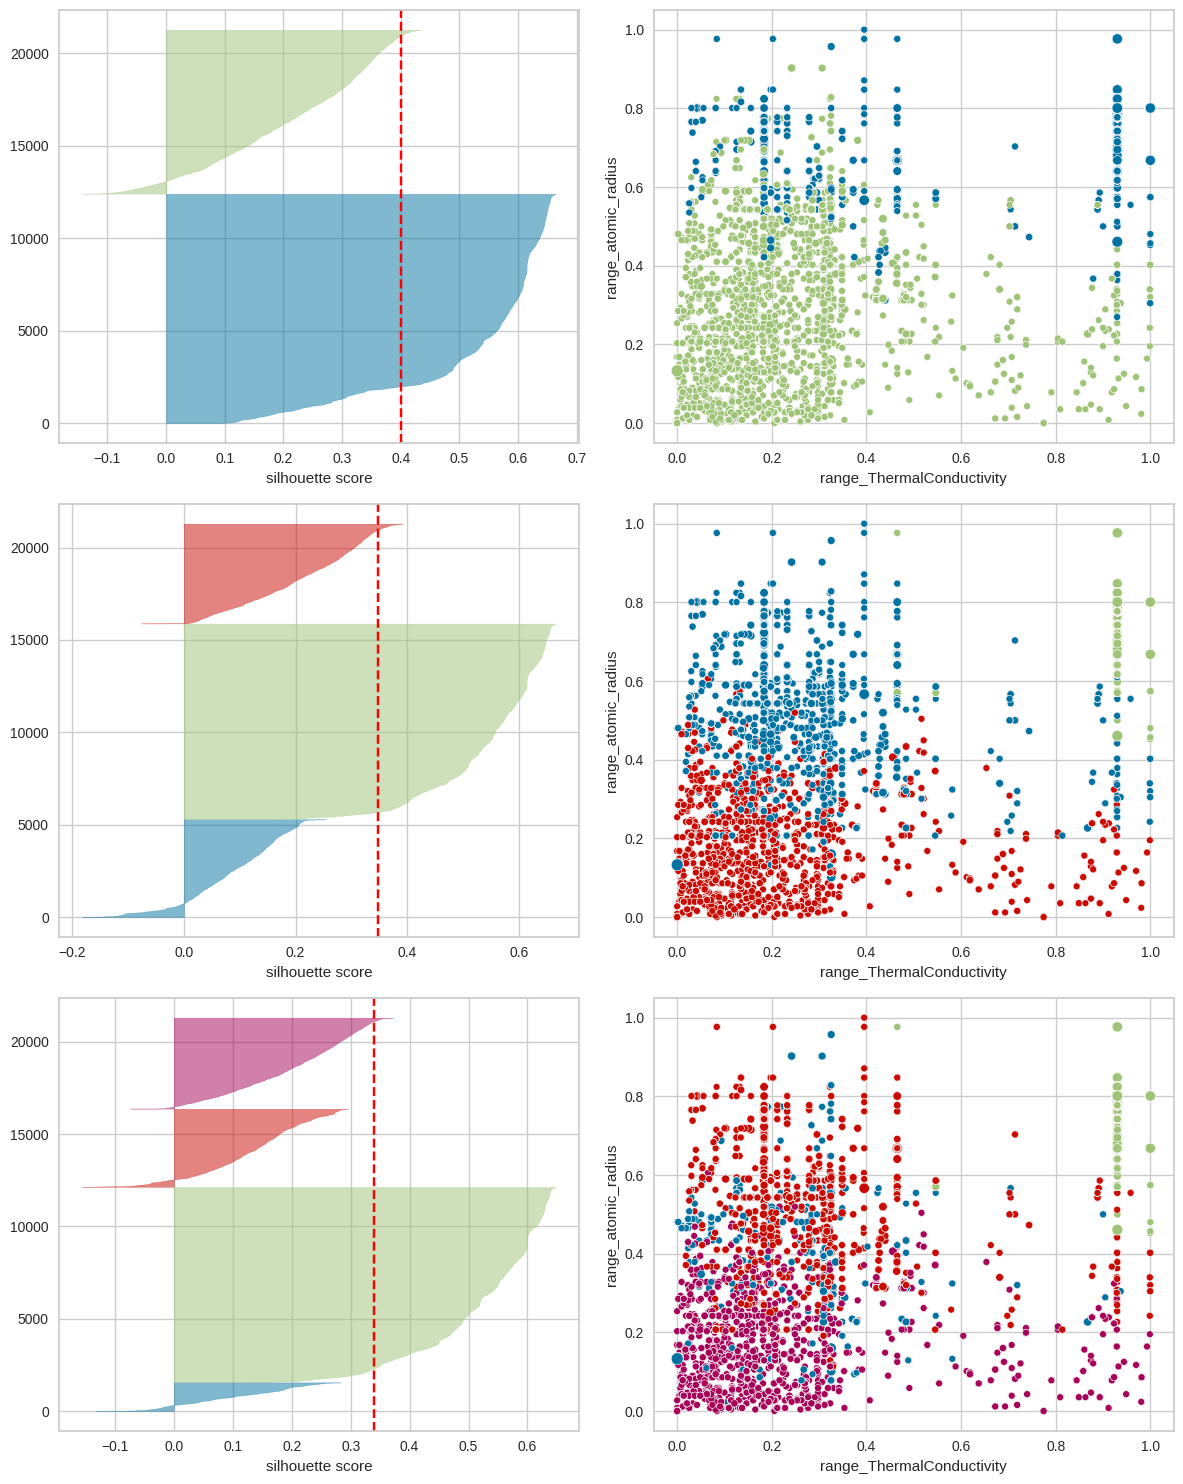

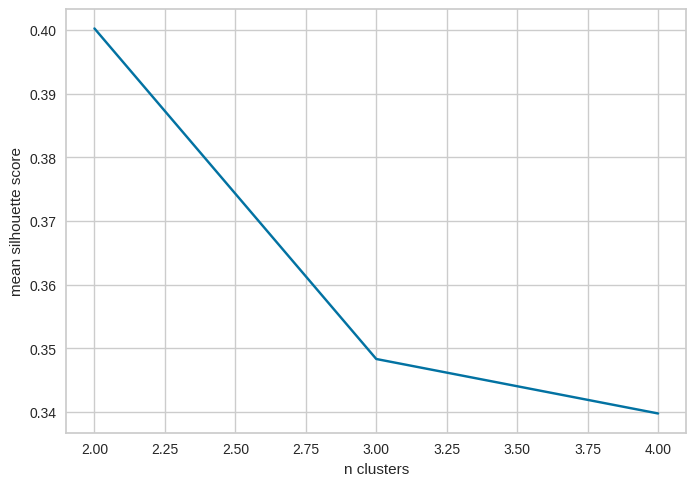

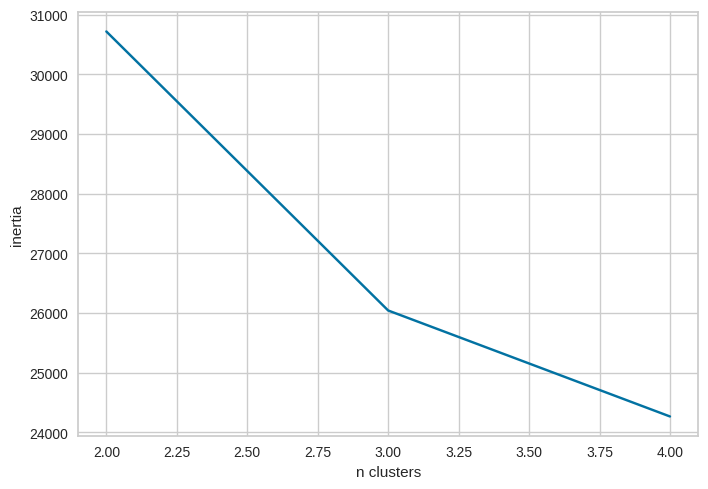

In [24]:
cluster_number_analysis(
    df=df_scaled,
    features=feature_columns,
    range_n_clusters=[2, 3, 4],
    features_to_plot = ["range_ThermalConductivity", "range_atomic_radius"]
)


### With reduction using PCA

In [16]:
df_pca = pd.read_csv(PATH_ROOT / "data/processed/train-minmax-no_cfs-pca.csv")
df_pca

,pc_0,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9,...,pc_72,pc_73,pc_74,pc_75,pc_76,pc_77,pc_78,pc_79,pc_80,critical_temp
0,-0.760072,0.632861,-0.005633,0.205954,-0.061266,0.009457,-0.056623,-0.050663,0.035798,-0.051830,...,-0.000273,0.000234,-0.000267,-0.000790,-0.000918,0.000206,0.001071,-0.000497,-0.000654,29.00
1,-0.954494,0.323756,-0.140948,0.014345,0.055140,-0.160309,-0.138492,0.154380,-0.031449,0.058003,...,-0.004173,-0.001792,0.001627,-0.003312,-0.001039,0.001707,0.000318,-0.000950,-0.000724,26.00
2,-0.725584,0.658725,-0.002053,0.225602,-0.054429,0.001070,-0.062875,-0.017677,0.069609,-0.045809,...,-0.001514,0.000066,-0.000112,-0.000278,-0.000531,-0.000062,0.000946,-0.000780,-0.000735,19.00
3,-0.743881,0.644796,-0.004184,0.215193,-0.058017,0.005267,-0.059692,-0.034942,0.051925,-0.048898,...,-0.000832,0.000144,-0.000222,-0.000558,-0.000739,0.000082,0.001022,-0.000627,-0.000692,22.00
4,-0.787915,0.613294,-0.007108,0.189978,-0.067076,0.017842,-0.050732,-0.078792,0.006858,-0.057322,...,0.000582,0.000425,-0.000213,-0.001141,-0.001208,0.000408,0.001117,-0.000281,-0.000589,23.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21258,0.458121,-0.366652,0.066112,-0.172551,0.454688,0.078101,-0.335912,-0.163454,-0.009760,-0.028998,...,-0.002973,-0.000280,-0.003667,-0.006852,-0.002239,-0.002947,-0.000601,0.004516,-0.001295,2.44
21259,-1.102695,0.132710,-0.137091,0.037698,0.130095,0.195354,-0.180732,-0.072055,-0.127050,0.221592,...,-0.004185,0.000463,-0.002399,0.002788,-0.000126,-0.000738,-0.000203,0.000877,-0.000086,122.10
21260,1.996372,0.184068,-0.168859,-0.252544,-0.084022,-0.138223,-0.168591,-0.062990,0.103902,0.064411,...,-0.004269,-0.001601,0.001318,0.000591,-0.000906,0.001942,0.001442,0.000461,-0.000004,1.98
21261,1.898402,0.085539,-0.155516,-0.321927,-0.143109,-0.001373,-0.048430,-0.218298,-0.054538,0.036676,...,-0.003125,-0.000754,0.000911,0.000178,-0.000696,0.001149,0.001564,-0.000636,0.000186,1.84


/tmp/ipykernel_2986354/1228126881.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


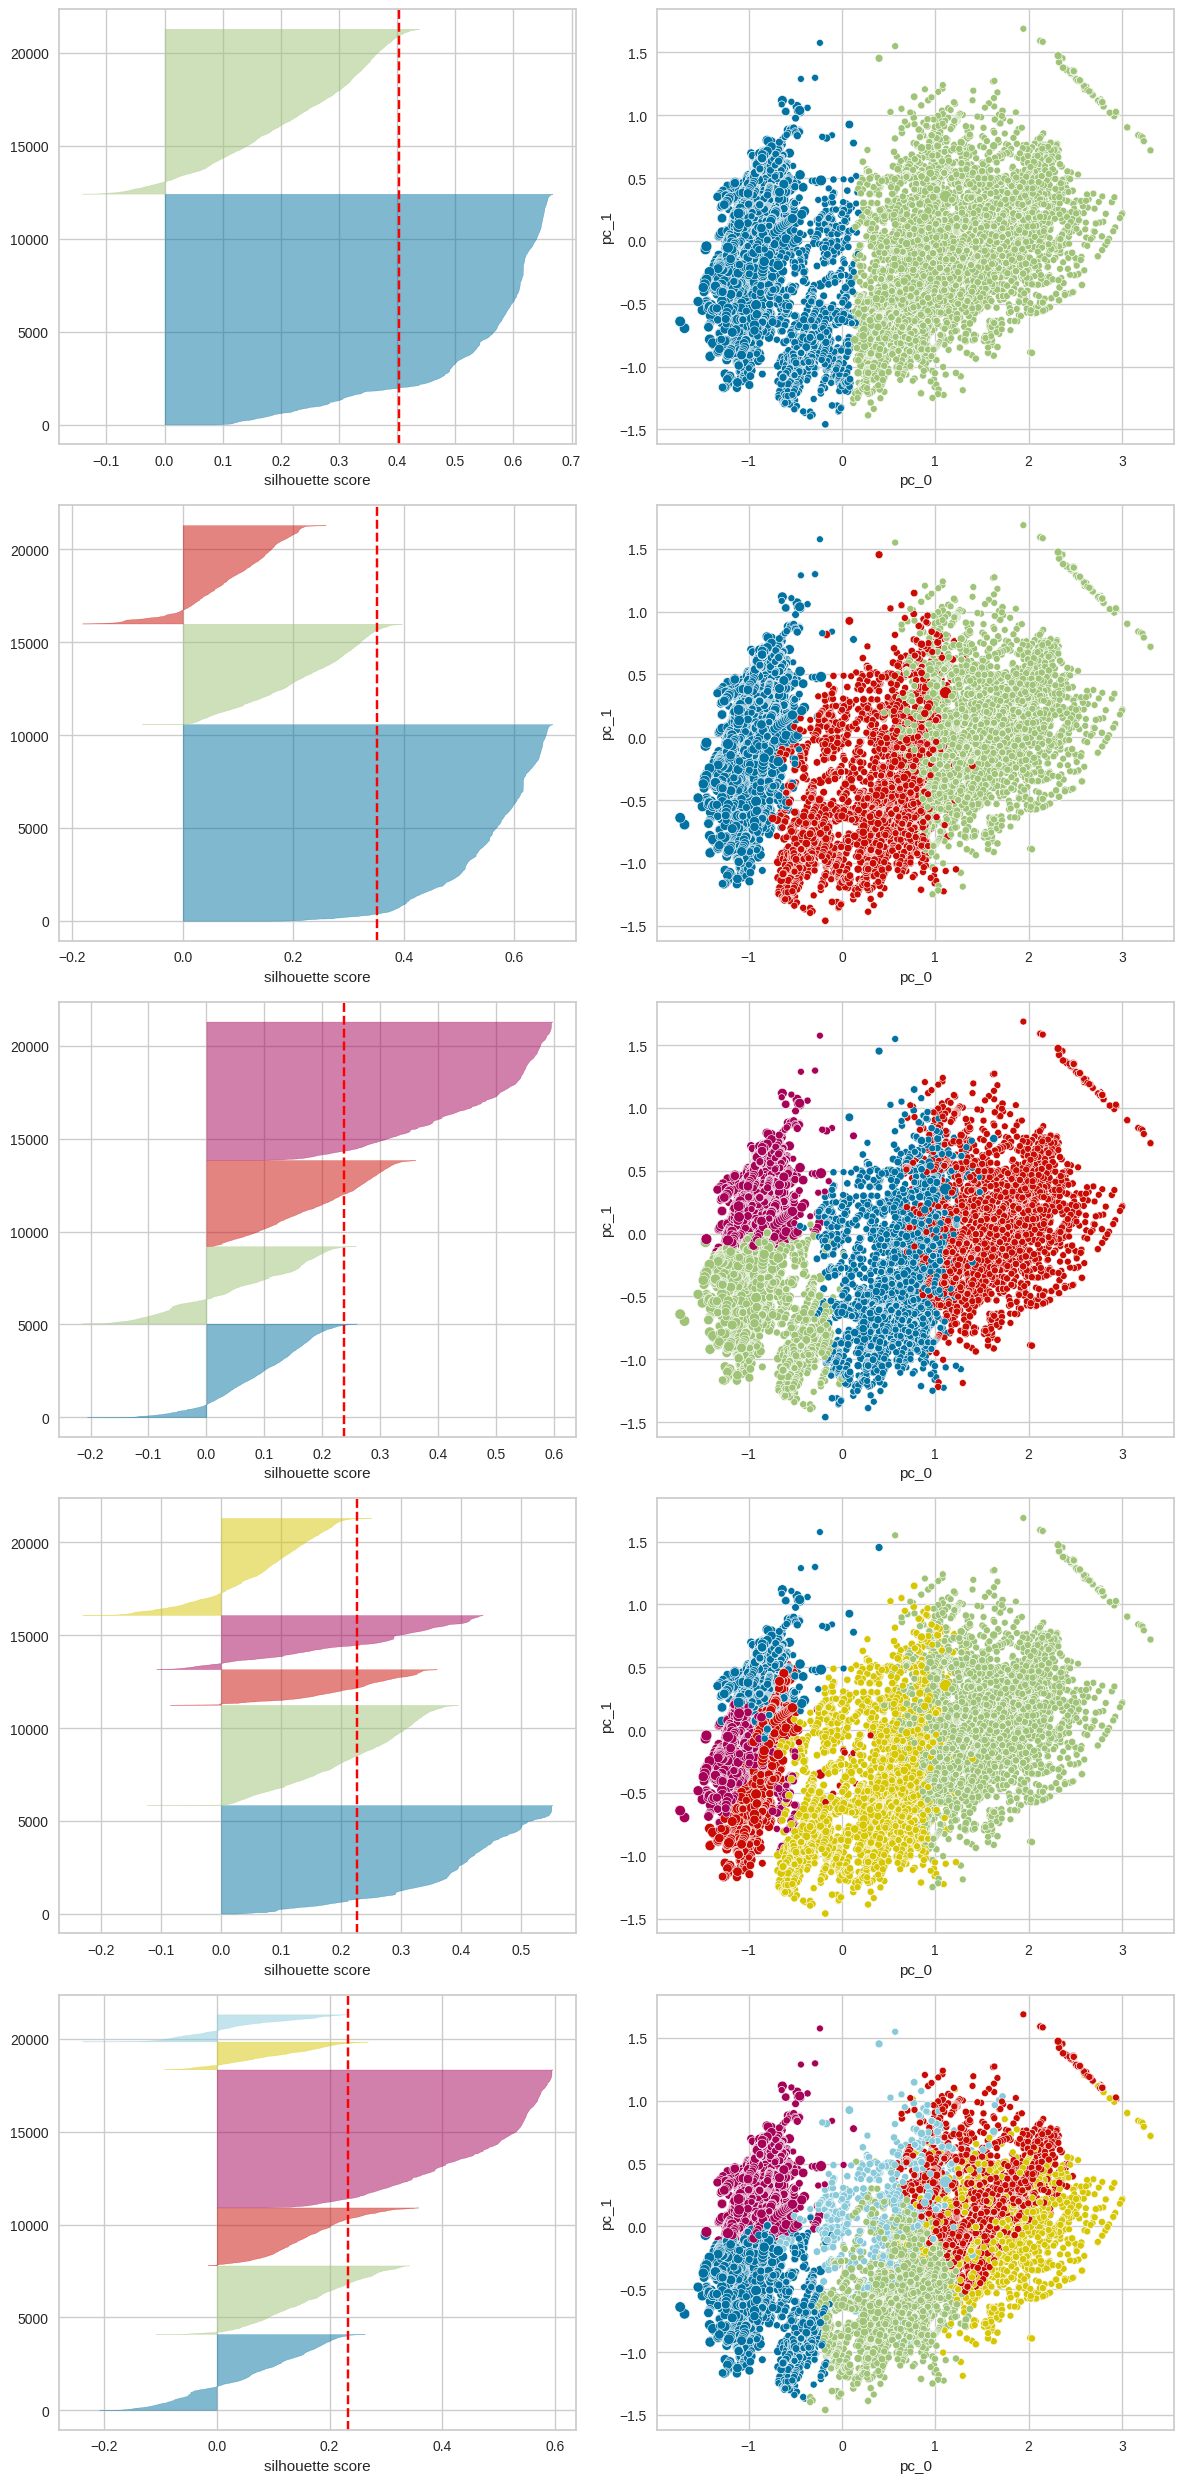

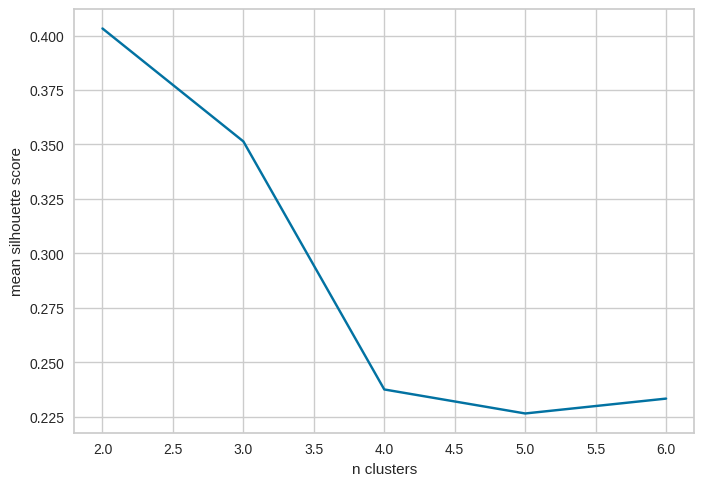

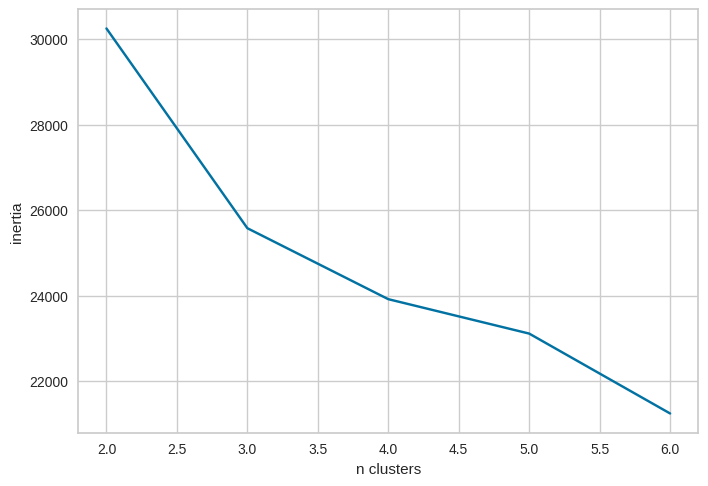

In [25]:
n_components = 30
cluster_number_analysis(df=df_pca, features=[f"pc_{i}" for i in range(n_components)], range_n_clusters=[2, 3, 4, 5, 6], features_to_plot=["pc_0", "pc_1"])

/tmp/ipykernel_2986354/1228126881.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


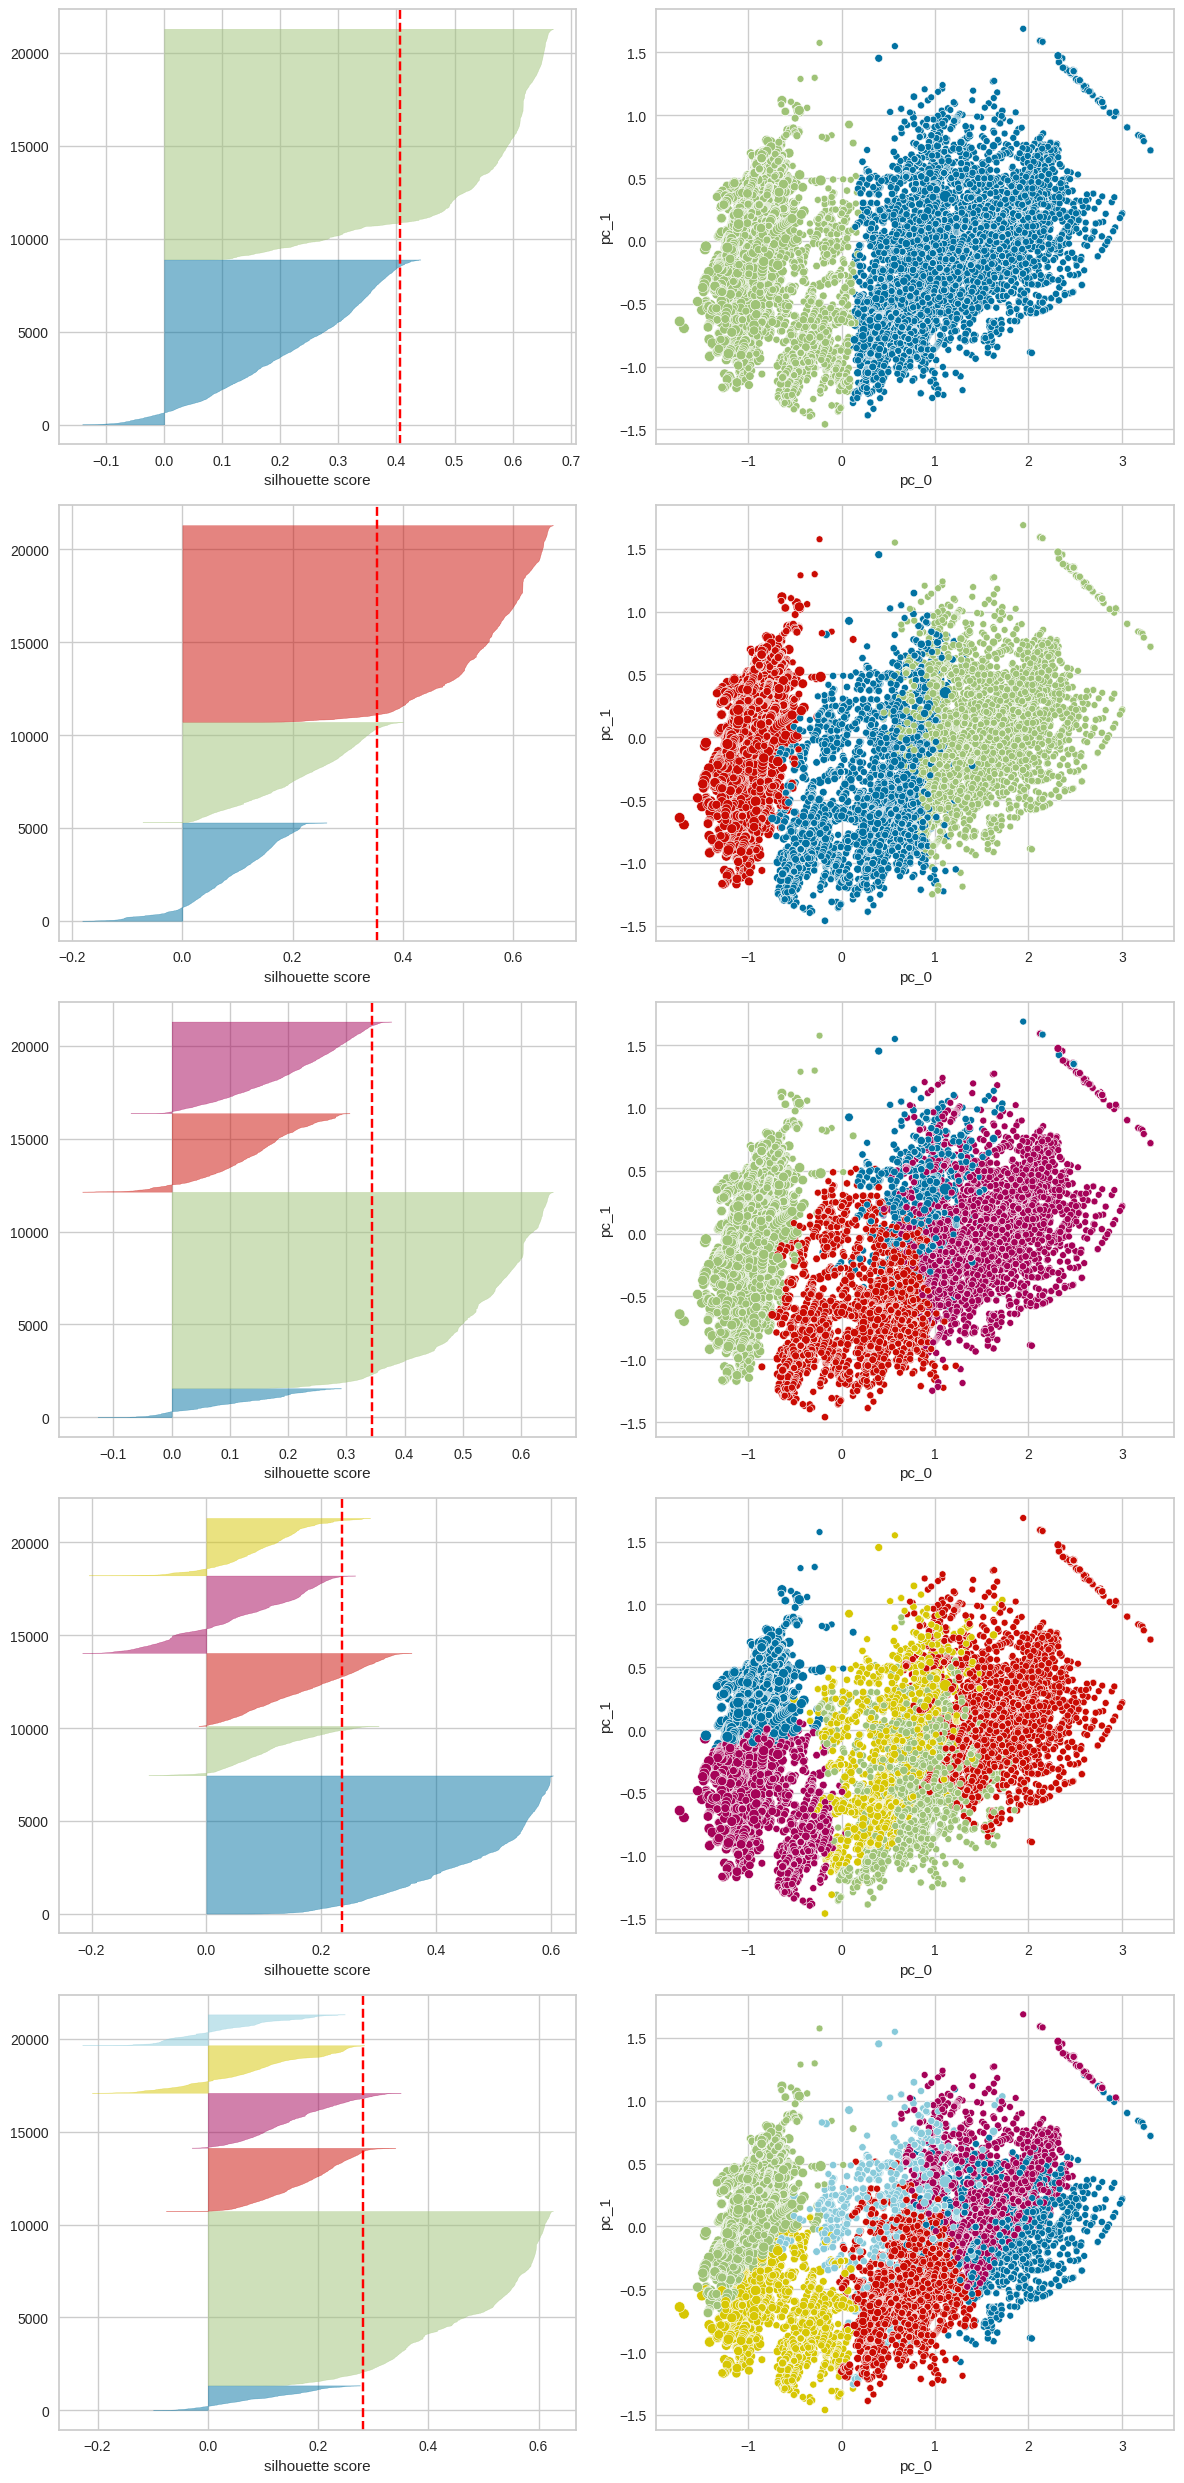

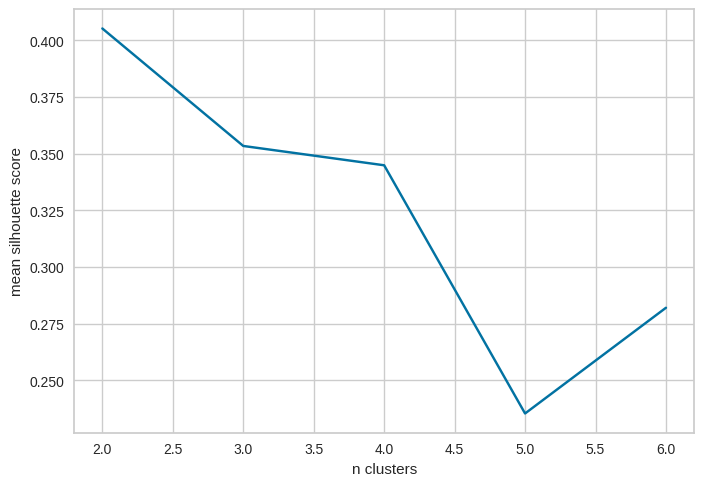

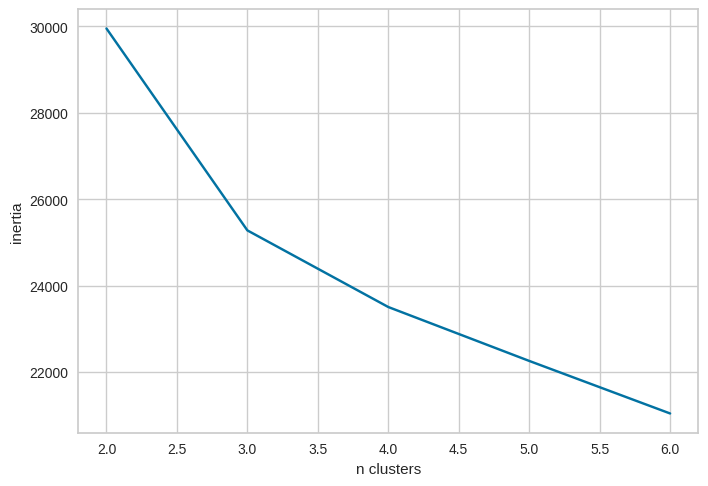

In [26]:
n_components = 25
cluster_number_analysis(df=df_pca, features=[f"pc_{i}" for i in range(n_components)], range_n_clusters=[2, 3, 4, 5, 6], features_to_plot=["pc_0", "pc_1"])

/tmp/ipykernel_2986354/1228126881.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


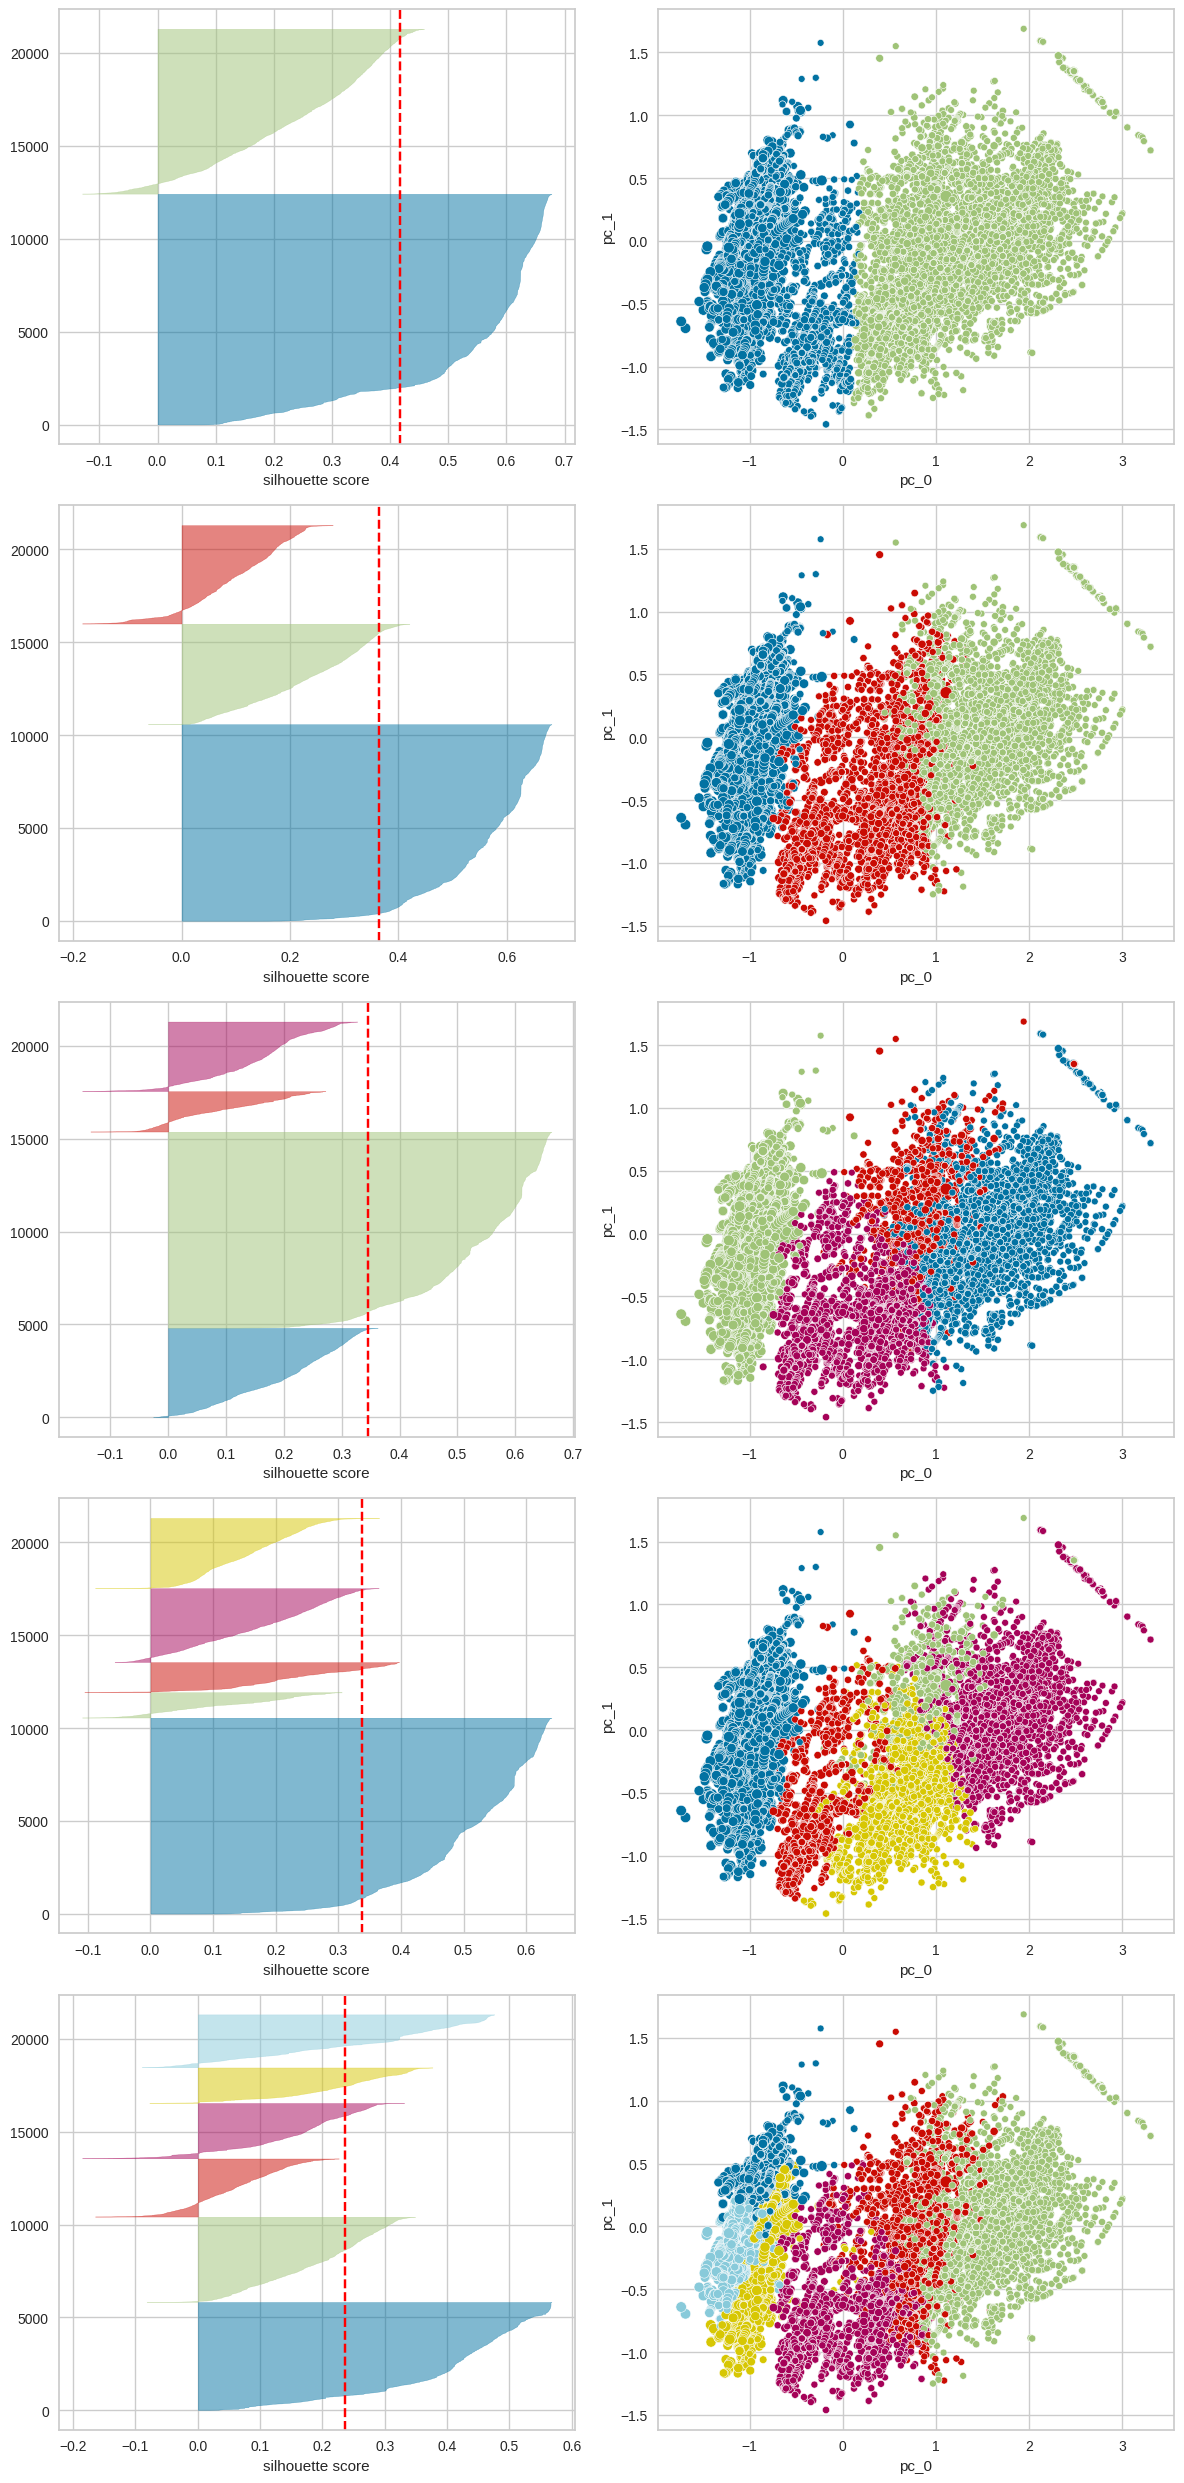

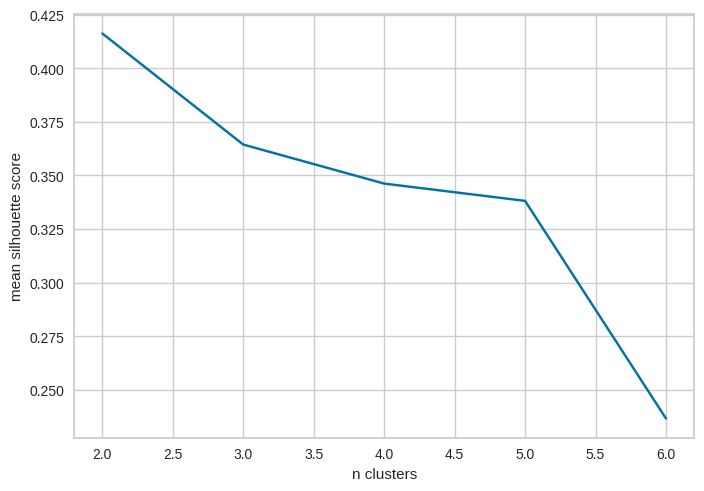

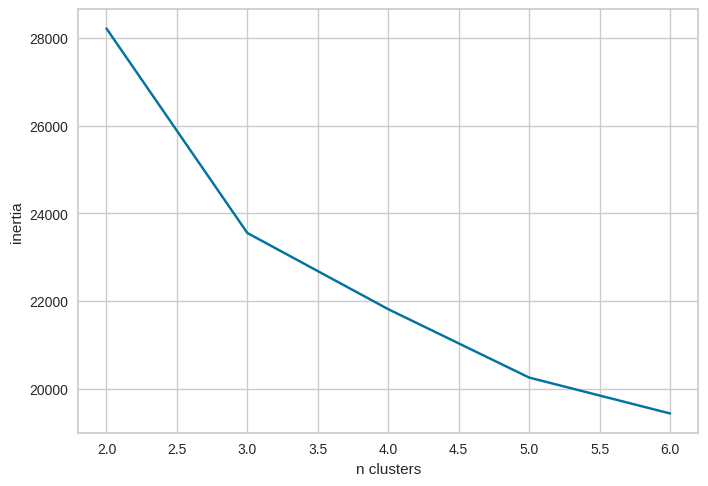

In [27]:
n_components = 15
cluster_number_analysis(df=df_pca, features=[f"pc_{i}" for i in range(n_components)], range_n_clusters=[2, 3, 4, 5, 6], features_to_plot=["pc_0", "pc_1"])

/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` ins

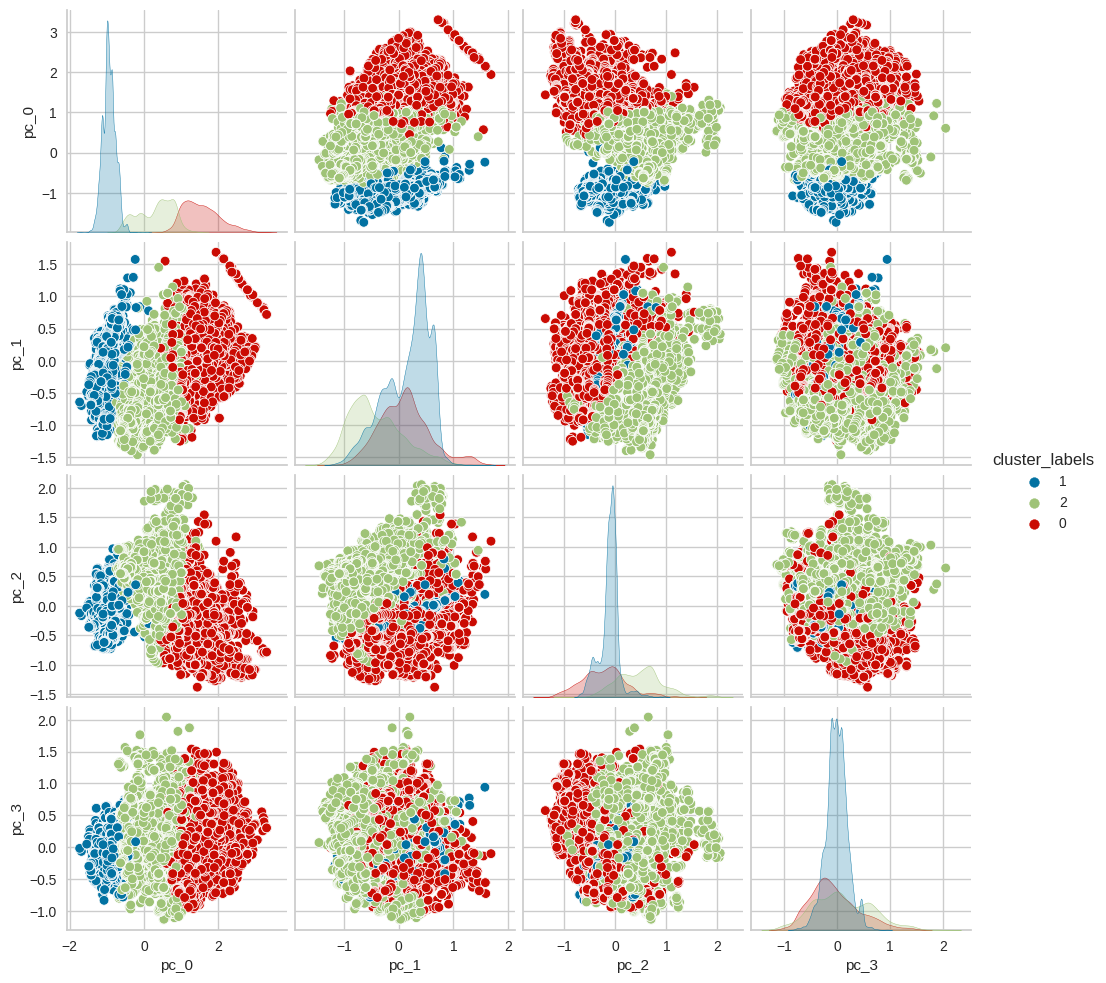

In [34]:
features = [f"pc_{i}" for i in range(15)]
clusterer = KMeans(n_clusters=3)
cluster_labels = clusterer.fit_predict(df_pca[features])

sns.pairplot(
    df_pca.assign(**{"cluster_labels": cluster_labels.astype(str)}),
    x_vars=[f"pc_{i}" for i in range(4)],
    y_vars=[f"pc_{i}" for i in range(4)],
    hue="cluster_labels",
)

/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` ins

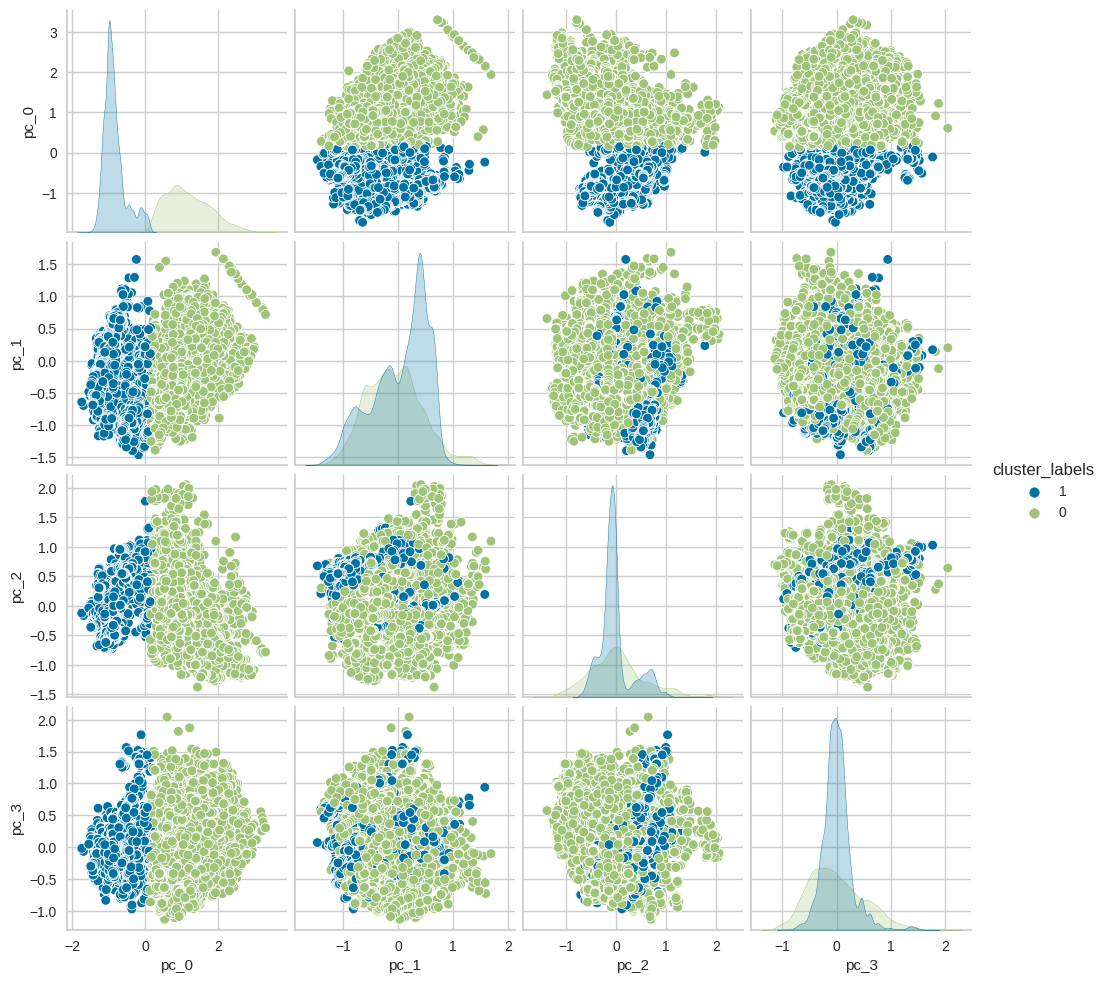

In [35]:
features = [f"pc_{i}" for i in range(15)]
clusterer = KMeans(n_clusters=2)
cluster_labels = clusterer.fit_predict(df_pca[features])

sns.pairplot(
    df_pca.assign(**{"cluster_labels": cluster_labels.astype(str)}),
    x_vars=[f"pc_{i}" for i in range(4)],
    y_vars=[f"pc_{i}" for i in range(4)],
    hue="cluster_labels",
)

/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/yparomau/.cache/pypoetry/virtualenvs/superconduct-tc-reg-45I6S9r8-py3.12/lib/python3.12/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` ins

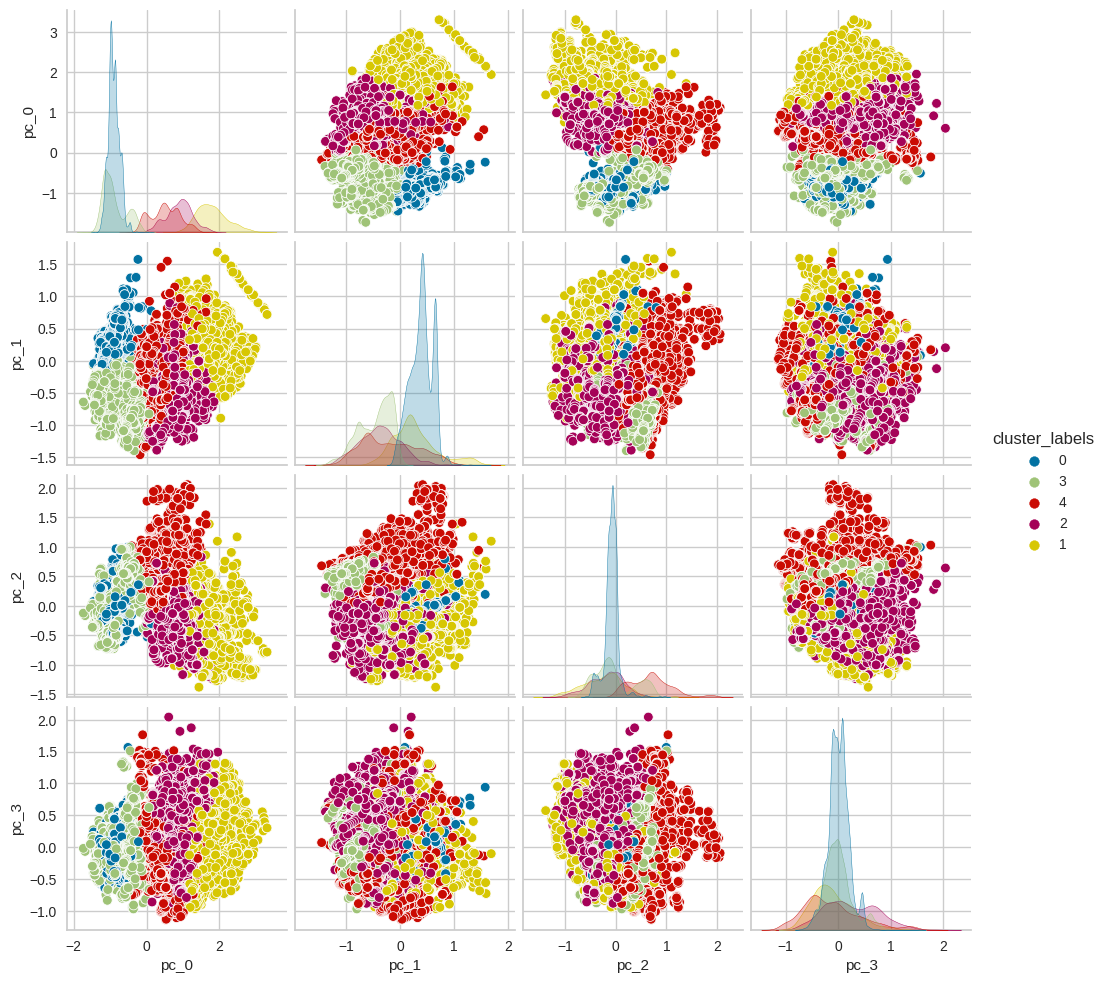

In [36]:
features = [f"pc_{i}" for i in range(15)]
clusterer = KMeans(n_clusters=5)
cluster_labels = clusterer.fit_predict(df_pca[features])

sns.pairplot(
    df_pca.assign(**{"cluster_labels": cluster_labels.astype(str)}),
    x_vars=[f"pc_{i}" for i in range(4)],
    y_vars=[f"pc_{i}" for i in range(4)],
    hue="cluster_labels",
)